In [1]:
## CHECKING FOR CHANGES SYNC

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as skl
from scipy.stats import pearsonr, linregress
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from IPython.display import display

path_dir = r"C:\Users\paolo\OneDrive\Desktop\Data Science Projects\02_retail_sales_forecasting_SYN"
stores = pd.read_csv(path_dir + r"\stores.csv")
sales = pd.read_csv(path_dir + r"\sales.csv")
features = pd.read_csv(path_dir + r"\features.csv")




## Challenge

**Build a Weekly Sales Forecasting Model**:

-Develop and evaluate a machine learning model to forecast future weekly sales for each store-department combination, leveraging historical sales patterns and relevant predictive features to support retail sales planning.


## Initial EDA

In [3]:

sales.info()
print("\n")
features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156000 entries, 0 to 155999
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   store_id      156000 non-null  int64  
 1   department    156000 non-null  int64  
 2   date          156000 non-null  object 
 3   weekly_sales  156000 non-null  float64
 4   is_holiday    156000 non-null  int64  
dtypes: float64(1), int64(3), object(1)
memory usage: 6.0+ MB


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7800 entries, 0 to 7799
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   store_id      7800 non-null   int64  
 1   date          7800 non-null   object 
 2   temperature   7800 non-null   float64
 3   fuel_price    7800 non-null   float64
 4   markdown_1    7800 non-null   float64
 5   markdown_2    7800 non-null   float64
 6   markdown_3    7800 non-null   float64
 7   markdown_4    7800 

In [4]:
display(stores.head(5))
display(features.head(5))
display(sales.head(5))

,store_id,store_type,store_size,region
0,1,A,213810,North
1,2,C,31639,East
2,3,B,102098,South
3,4,B,88289,North
4,5,A,218696,North


,store_id,date,temperature,fuel_price,markdown_1,markdown_2,markdown_3,markdown_4,markdown_5,cpi,unemployment,is_holiday,holiday_name,season
0,1,2022-01-01,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
1,1,2022-01-08,46.03,3.67,1356.75,2486.21,1427.01,983.27,2442.13,196.91,8.62,0,NaN,Winter
2,1,2022-01-15,25.96,5.46,3861.22,596.15,22.09,2854.11,3180.86,267.48,8.40,0,NaN,Winter
3,1,2022-01-22,25.92,3.58,579.35,2589.31,2493.19,1158.14,286.01,217.32,5.28,0,NaN,Winter
4,1,2022-01-29,78.37,4.41,4436.06,1416.64,478.38,2496.36,3423.53,247.35,8.40,0,NaN,Winter


,store_id,department,date,weekly_sales,is_holiday
0,1,1,2022-01-01,119075.96,1
1,1,2,2022-01-01,119107.85,1
2,1,3,2022-01-01,84369.88,1
3,1,4,2022-01-01,88445.24,1
4,1,5,2022-01-01,65159.85,1


In [5]:
retail_sales = sales.merge(
    stores,
    on="store_id",
    how="left"
).merge(
    features,
    on=["store_id", "date"],
    how="left"
)

retail_sales = pd.DataFrame(retail_sales)

In [6]:
# 1. Inspecting Structure, Data Types, and Unique Values
def inspect_dataframe(df):
    print(f"Rows: {df.shape[0]:,}")
    print(f"Columns: {df.shape[1]}")

    summary = pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.values,
        "Unique Values": df.nunique().values
    })

    display(summary)

inspect_dataframe(retail_sales)


Rows: 156,000
Columns: 20


,Column,Data Type,Unique Values
0,store_id,int64,50
1,department,int64,20
2,date,object,156
3,weekly_sales,float64,154981
4,is_holiday_x,int64,2
5,store_type,object,3
6,store_size,int64,50
7,region,object,4
8,temperature,float64,4974
9,fuel_price,float64,301


In [7]:
#2. Quick Scan and Determining Granularity of the Data
display(retail_sales.head(22))
display(retail_sales["date"].agg(["min", "max"])) #min and max dates

# Granularity: One observation/row represents one store by department by week (date)
# Dates: From 2022-01-01 - 2024-12-21


,store_id,department,date,weekly_sales,is_holiday_x,store_type,store_size,region,temperature,fuel_price,markdown_1,markdown_2,markdown_3,markdown_4,markdown_5,cpi,unemployment,is_holiday_y,holiday_name,season
0,1,1,2022-01-01,119075.96,1,A,213810,North,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
1,1,2,2022-01-01,119107.85,1,A,213810,North,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
2,1,3,2022-01-01,84369.88,1,A,213810,North,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
3,1,4,2022-01-01,88445.24,1,A,213810,North,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
4,1,5,2022-01-01,65159.85,1,A,213810,North,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
5,1,6,2022-01-01,99015.94,1,A,213810,North,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
6,1,7,2022-01-01,157858.77,1,A,213810,North,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
7,1,8,2022-01-01,58702.96,1,A,213810,North,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
8,1,9,2022-01-01,199677.02,1,A,213810,North,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
9,1,10,2022-01-01,139744.34,1,A,213810,North,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter


min    2022-01-01
max    2024-12-21
Name: date, dtype: object

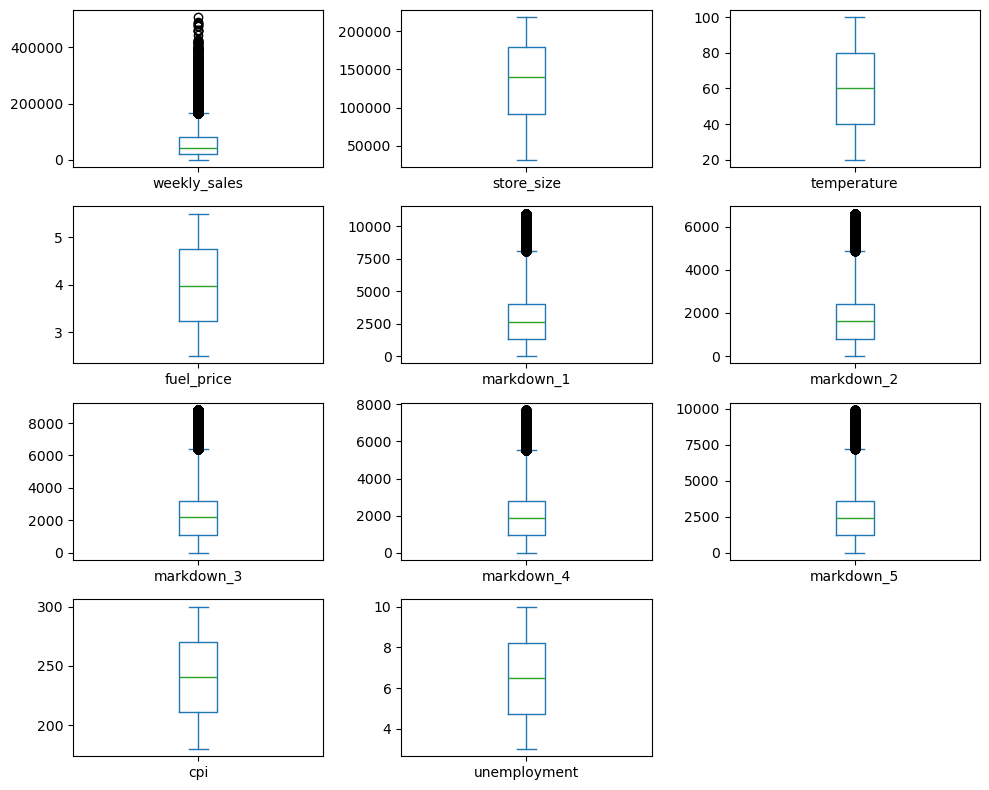

Missing Values:


store_id             0
department           0
date                 0
weekly_sales         0
is_holiday_x         0
store_type           0
store_size           0
region               0
temperature          0
fuel_price           0
markdown_1           0
markdown_2           0
markdown_3           0
markdown_4           0
markdown_5           0
cpi                  0
unemployment         0
is_holiday_y         0
holiday_name    138000
season               0
dtype: int64

In [8]:
#3. Check Numerical Variables; Missing Values & Anomalies
## Numerical Variables
variables = [
    "weekly_sales",
    "store_size", 
    "temperature", 
    "fuel_price",
    "markdown_1", #promotional markdown values
    "markdown_2", #promotional markdown values
    "markdown_3", #promotional markdown values
    "markdown_4", #promotional markdown values
    "markdown_5", #promotional markdown values
    "cpi",
    "unemployment"
]

retail_sales[variables].plot( #
    kind="box",
    subplots=True,
    layout=(4, 3),
    figsize=(10, 8),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

print("Missing Values:")
retail_sales.isnull().sum() # missing values


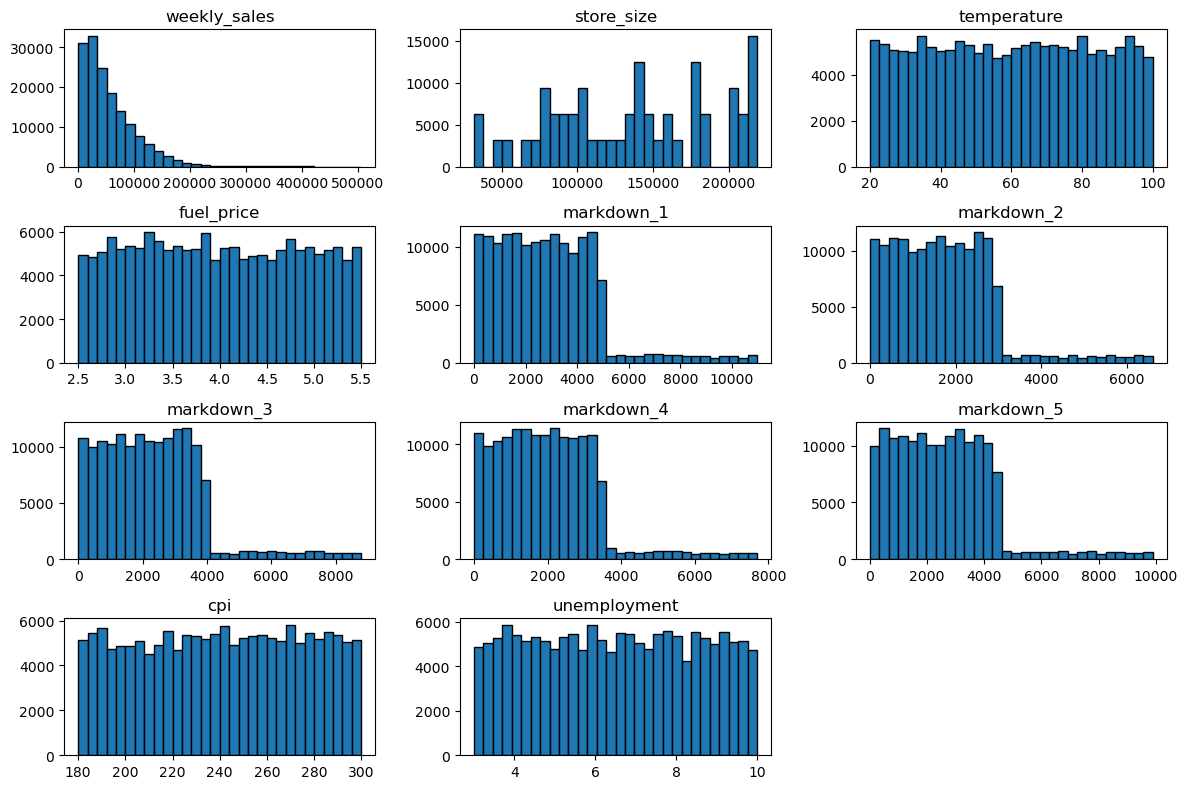

,weekly_sales,store_size,temperature,fuel_price,markdown_1,markdown_2,markdown_3,markdown_4,markdown_5,cpi,unemployment
min,819.66,31639.00,20.02,2.50,0.18,0.20,1.01,1.13,0.14,180.00,3.00
max,505958.73,218696.00,99.97,5.50,10977.07,6599.72,8798.15,7692.88,9891.19,299.99,10.00
median,43394.87,140736.50,60.06,3.97,2652.50,1612.57,2174.60,1862.98,2417.90,240.94,6.49
mean,56503.49,136626.44,59.88,3.99,2831.84,1708.09,2295.92,1982.04,2561.79,240.47,6.49


weekly_sales    1.60
store_size     -0.12
temperature    -0.00
fuel_price      0.03
markdown_1      1.18
markdown_2      1.20
markdown_3      1.19
markdown_4      1.17
markdown_5      1.19
cpi            -0.03
unemployment    0.01
dtype: float64

In [9]:

#4. Distribution of Data
# Plot histograms
retail_sales[variables].hist(
    bins=30,
    figsize=(12, 8),
    layout=(4, 3),
    edgecolor="black",
    grid=False
)

plt.tight_layout()
plt.show()

# Aggregated Measures of Central Tendency
display(retail_sales[variables].agg(["min", "max", "median", "mean"]).round(2))

# Skewness
display(retail_sales[variables].skew().round(2))


## Initial EDA Findings
Dataset Overview
1. **Dataset Size** — 156,000 rows × 18 columns
2. **Granularity** — One observation per store × department × week (date)
3. **Calendar Coverage** — January 1, 2022 – December 21, 2024
4. **Variables of Interest** — `weekly_sales` (target variable), `temperature`, `fuel_price`, `markdown_1`–`markdown_5`, `cpi`, and `unemployment`

Data Quality
1. **Missing Values** — No missing values found.
2. **Duplicate Records** — No duplicates found based on the unique identifiers (`store_id`, `department`, and `date`).
3. **Potential Outliers** — Potential outliers identified in `weekly_sales`; further investigation is needed to determine whether they represent legitimate high-sales observations or data anomalies.

Observations:
- `weekly_sales` and `markdown_1`– `markdown_5` exhibit right-skewed distributions with potential outliers.

Analyst Inferences and Hypotheses:
- High sales values may reflect differences across stores, departments, holidays, or promotional periods.
- Markdown values, temperature, fuel prices, and holidays may help explain sales variations. Their relationships and predictive value remain to be tested.


## Objective
- Build and evaluate a reliable machine learning model to forecast weekly sales revenue for each store over the next four weeks.

## Inferences on Sales

In [10]:
## Inferences on Sales

# Historical + Seasonal Data Signals
# 1. Does historical sales pattern help predict future sales?
#    Potential features: lag_1, lag_2, lag_4, lag_8, lag_16, is_holiday, week_of_year, week_of_month, month_

# Store Characteritic Signals (Model B
# 2. Does sales differ across stores, department, store types, store_size?
#    Potential features: store_id, department_id, store_types, store_size
#    Feature: Include

# Economic Indicators Signals
# 3. Are economic indicators associated with weekly sales?
#    Potential features: fuel_price, unemployment, cpi


## Targetted EDA & Hypotheses on Inferences

## Historical Sales Lag
Historical sales may help predict future weekly sales. Lag features (e.g., 1, 2, 4, 8, 12, and 16 weeks prior) capture sales at specific intervals, while rolling means capture recent sales trends by averaging sales over a defined window.

## Seasonality and Holiday Effects
Weekly sales exhibit a recurring seasonal pattern, rising sharply in September and peaking in November–December before declining (Figure A). Holiday weeks also show differences in average weekly sales compared with non-holiday weeks (Figures B).

This seasonal pattern appears consistent across stores (Figures D and E), suggesting that `month` and `is_holiday` are promising candidate predictors for capturing seasonal fluctuations in weekly sales.

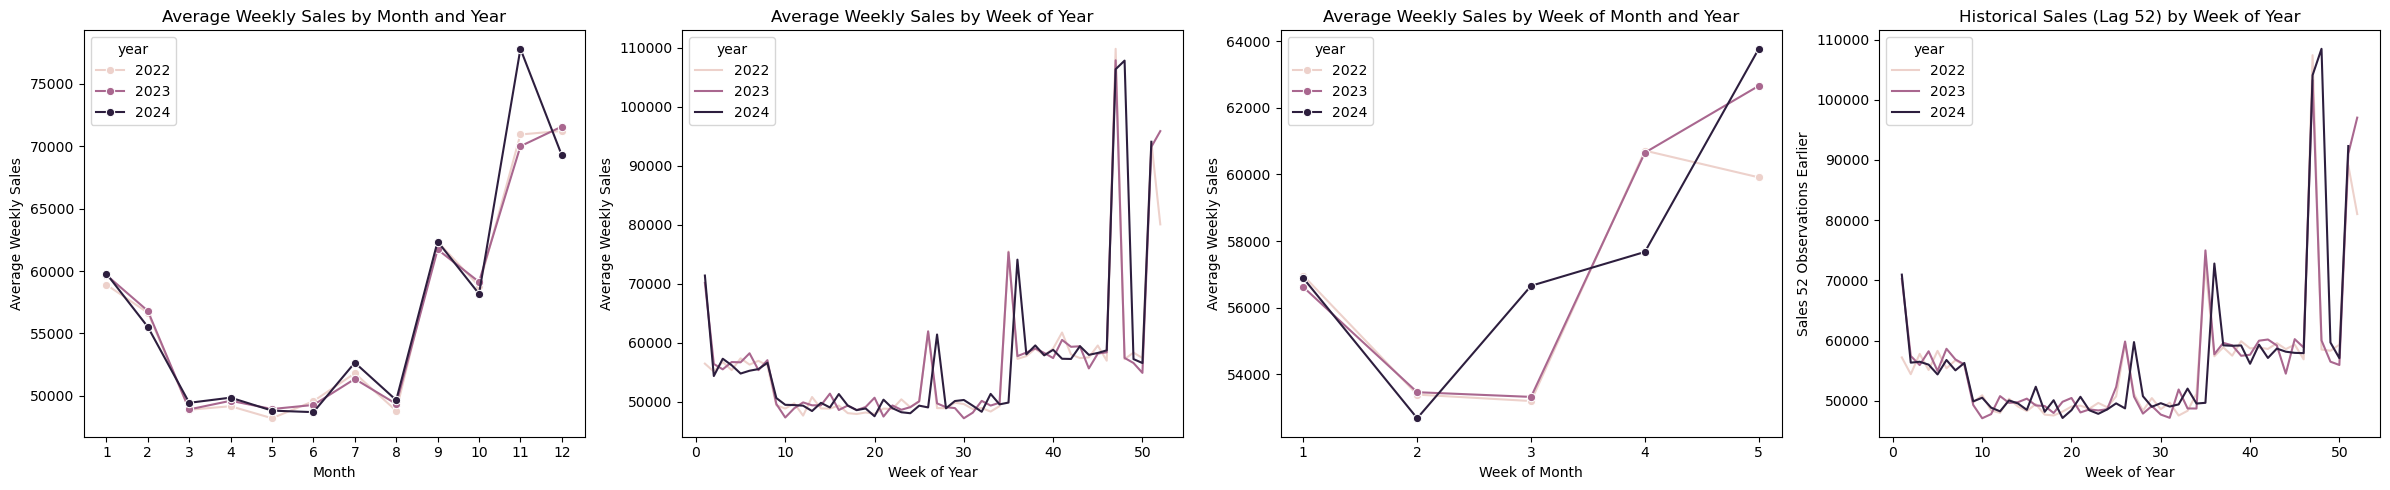

In [11]:
retail_sales["date"] = pd.to_datetime(retail_sales["date"])
retail_sales["month"] = retail_sales["date"].dt.month
retail_sales["year"] = retail_sales["date"].dt.year
retail_sales["week_of_year"] = retail_sales["date"].dt.isocalendar().week.astype(int)
retail_sales["week_of_month"] = ((retail_sales["date"].dt.day - 1) // 7) + 1

# Create lag 52
retail_sales = retail_sales.sort_values("date").copy()
retail_sales["lag_52"] = retail_sales["weekly_sales"].shift(52)

# Aggregate sales by year and calendar feature
monthly_sales = retail_sales.groupby(["year", "month"])["weekly_sales"].mean().reset_index()
weekly_year_sales = retail_sales.groupby(["year", "week_of_year"])["weekly_sales"].mean().reset_index()
weekly_month_sales = retail_sales.groupby(["year", "week_of_month"])["weekly_sales"].mean().reset_index()
lag52_sales = retail_sales.dropna(subset=["lag_52"]).groupby(["year", "week_of_year"])["lag_52"].mean().reset_index()

fig, axes = plt.subplots(1, 4, figsize=(24, 5))

# Figure A: Month, separate line per year
sns.lineplot(data=monthly_sales, x="month", y="weekly_sales", hue="year", marker="o", ax=axes[0])
axes[0].set_title("Average Weekly Sales by Month and Year")
axes[0].set_xticks(range(1, 13))
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Average Weekly Sales")

# Figure B: Week of year, separate line per year
sns.lineplot(data=weekly_year_sales, x="week_of_year", y="weekly_sales", hue="year", ax=axes[1])
axes[1].set_title("Average Weekly Sales by Week of Year")
axes[1].set_xlabel("Week of Year")
axes[1].set_ylabel("Average Weekly Sales")

# Figure C: Week of month, separate line per year
sns.lineplot(data=weekly_month_sales, x="week_of_month", y="weekly_sales", hue="year", marker="o", ax=axes[2])
axes[2].set_title("Average Weekly Sales by Week of Month and Year")
axes[2].set_xticks([1, 2, 3, 4, 5])
axes[2].set_xlabel("Week of Month")
axes[2].set_ylabel("Average Weekly Sales")

# Figure D: Lag 52, separate line per year
sns.lineplot(data=lag52_sales, x="week_of_year", y="lag_52", hue="year", ax=axes[3])
axes[3].set_title("Historical Sales (Lag 52) by Week of Year")
axes[3].set_xlabel("Week of Year")
axes[3].set_ylabel("Sales 52 Observations Earlier")

plt.tight_layout()
plt.show()

## Candidate Features: Month, week_of_year, lag_52
## Rationale: Investigate recurring seasonal patterns and historical sales from approximately one year earlier.

In [12]:
retail_sales["month"] = retail_sales["date"].dt.month

holiday_monthly_sales = retail_sales.groupby(
    ["month", "is_holiday_x"]
)["weekly_sales"].mean().unstack()

holiday_monthly_sales.columns = ["Non-Holiday", "Holiday"]

holiday_monthly_sales["Holiday Growth %"] = (
    (holiday_monthly_sales["Holiday"] - holiday_monthly_sales["Non-Holiday"])
    / holiday_monthly_sales["Non-Holiday"]
) * 100

holiday_monthly_sales.round(2)

,Non-Holiday,Holiday,Holiday Growth %
month,,,
1,55989.72,70809.51,26.47
2,56327.29,NaN,NaN
3,49096.70,NaN,NaN
4,49509.00,NaN,NaN
5,48642.59,NaN,NaN
6,49130.17,NaN,NaN
7,49199.02,61704.27,25.42
8,49289.19,NaN,NaN
9,58257.84,74964.67,28.68


## Historical data across 50 stores shows a very strong positive relationship between store size and average weekly sales (Pearson r = 0.991, R² = 0.982, p < 0.001). This supports including `store_size` as a candidate predictive feature for weekly sales forecasting.

Number of stores: 50
Pearson correlation: 0.9908
P-value: 0.000000
R-squared: 0.9817
Slope: 0.5157


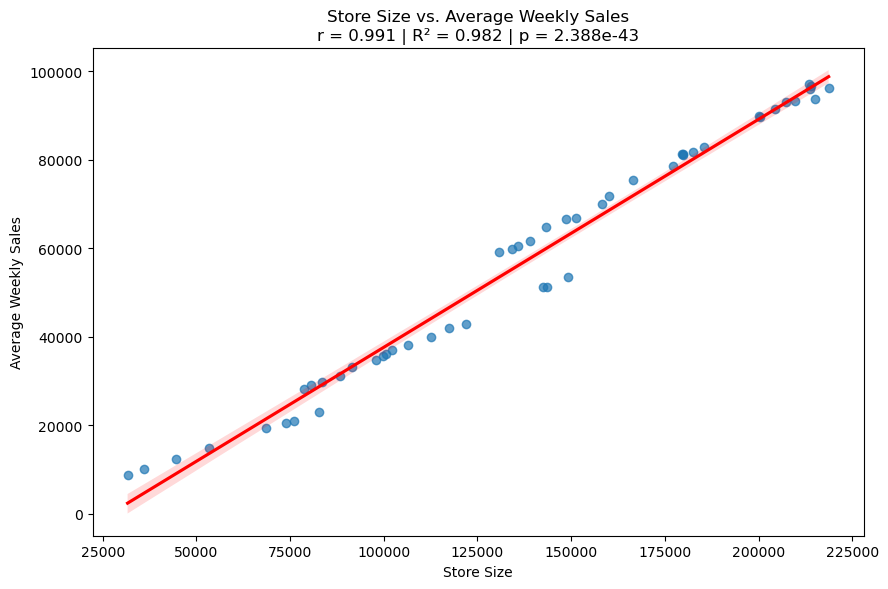

In [13]:
# Store Characteritic Signals
# 2. Does sales differ across stores, department, store types, store_size?
#    Potential features: store_id, department_id, store_types, store_size

# 1. Each observation represents one store
store_sales = (
    retail_sales.groupby("store_id", as_index=False)
    .agg(
        store_size=("store_size", "first"),
        avg_weekly_sales=("weekly_sales", "mean")
    )
    .dropna(subset=["store_size", "avg_weekly_sales"])
)

# 2. Measure correlation and fit linear regression
x = store_sales["store_size"]
y = store_sales["avg_weekly_sales"]

r, p_value = pearsonr(x, y)
regression = linregress(x, y)

print(f"Number of stores: {len(store_sales)}")
print(f"Pearson correlation: {r:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"R-squared: {regression.rvalue**2:.4f}")
print(f"Slope: {regression.slope:.4f}")

# 3. Visualize the relationship
plt.figure(figsize=(9, 6))

sns.regplot(
    data=store_sales,
    x="store_size",
    y="avg_weekly_sales",
    ci=95,
    scatter_kws={"alpha": 0.7},
    line_kws={"color": "red"}
)

plt.title(
    f"Store Size vs. Average Weekly Sales\n"
    f"r = {r:.3f} | R² = {regression.rvalue**2:.3f} | p = {p_value:.4g}"
)
plt.xlabel("Store Size")
plt.ylabel("Average Weekly Sales")
plt.tight_layout()
plt.show()

## Store types with higher average weekly sales also tend to have larger average store sizes. This suggests that store type may serve as a strong candidate feature for predicting weekly sales, potentially capturing differences in store scale and sales performance.

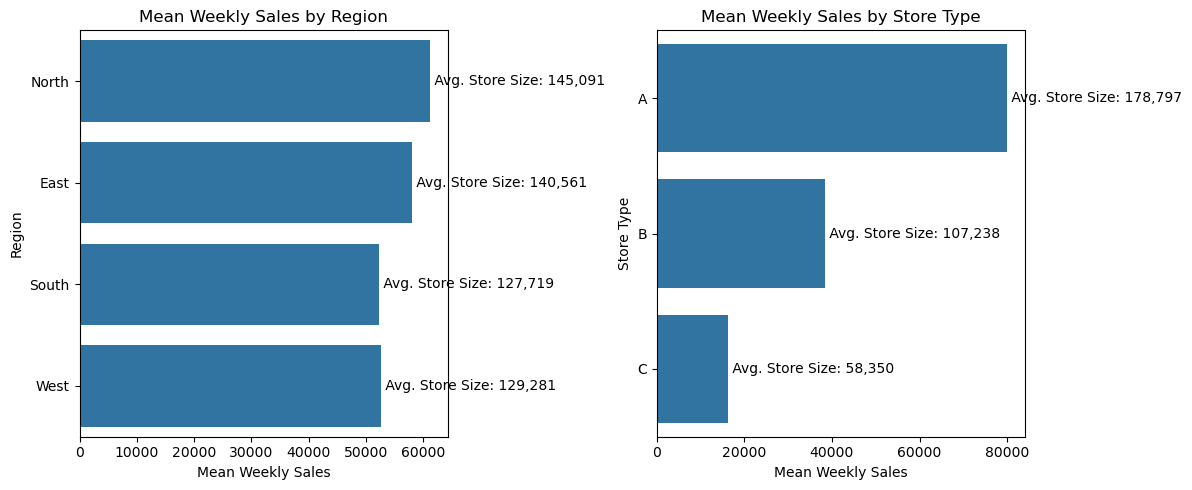

In [14]:

# Calculate average store size by region and store type
avg_size_region = retail_sales.groupby("region")["store_size"].mean().to_dict()
avg_size_type = retail_sales.groupby("store_type")["store_size"].mean().to_dict()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Mean Weekly Sales by Region
sns.barplot(
    data=retail_sales, x="weekly_sales", y="region",
    errorbar=None, ax=axes[0]
)
axes[0].set_title("Mean Weekly Sales by Region")
axes[0].set_xlabel("Mean Weekly Sales")
axes[0].set_ylabel("Region")

for i, region in enumerate(axes[0].get_yticklabels()):
    axes[0].text(
        axes[0].patches[i].get_width(),
        i,
        f" Avg. Store Size: {avg_size_region[region.get_text()]:,.0f}",
        va="center"
    )

# Mean Weekly Sales by Store Type
sns.barplot(
    data=retail_sales, x="weekly_sales", y="store_type",
    errorbar=None, ax=axes[1]
)
axes[1].set_title("Mean Weekly Sales by Store Type")
axes[1].set_xlabel("Mean Weekly Sales")
axes[1].set_ylabel("Store Type")

for i, store_type in enumerate(axes[1].get_yticklabels()):
    axes[1].text(
        axes[1].patches[i].get_width(),
        i,
        f" Avg. Store Size: {avg_size_type[store_type.get_text()]:,.0f}",
        va="center"
    )

plt.tight_layout()
plt.show()


## Economic indicators (`fuel_price`, `unemployment`, `cpi`) show near-zero Pearson correlations with weekly sales across all stores combined, indicating little to no linear relationship. However, they may still provide predictive value when combined with other features, so they will be retained as candidate features for model evaluation.

In [15]:
# Economic Indicators Signals
# 4. Are economic indicators associated with weekly sales?
#    Potential features: fuel_price, unemployment, cpi

# Economic Indicators vs Weekly Sales

econ_indicators = ["fuel_price", "unemployment", "cpi"]

for indicator in econ_indicators:
    correlation = retail_sales[indicator].corr(retail_sales["weekly_sales"])
    print(f"{indicator}: {correlation:.3f}")

fuel_price: -0.002
unemployment: -0.007
cpi: -0.002


## Feature Engineering

In [16]:

# ==========================================
# 1. PREPARE DATASET
# ==========================================
retail_sales["date"] = pd.to_datetime(retail_sales["date"])

model_data = retail_sales.sort_values(
    ["store_id", "department", "date"]
).copy()


# ==========================================
# 2. HISTORICAL SALES FEATURES
# ==========================================

# Lag features
lag_windows = [1, 2, 4, 8]

for lag in lag_windows:
    model_data[f"lag_{lag}"] = (
        model_data.groupby(["store_id", "department"])["weekly_sales"]
        .shift(lag)
    )

# Rolling statistics
rolling_windows = [2, 4, 8]

for window in rolling_windows:
    sales_history = model_data.groupby(
        ["store_id", "department"]
    )["weekly_sales"]

    model_data[f"rolling_mean_{window}"] = (
        sales_history.transform(
            lambda x: x.shift(1).rolling(window).mean()
        )
    )

    model_data[f"rolling_std_{window}"] = (
        sales_history.transform(
            lambda x: x.shift(1).rolling(window).std()
        )
    )


# ==========================================
# 3. SEASONALITY & CALENDAR FEATURES
# ==========================================

model_data["month"] = model_data["date"].dt.month

model_data["week_of_year"] = (
    model_data["date"].dt.isocalendar().week.astype(int)
)


# ==========================================
# 4. DEFINE MODEL A FEATURES
# ==========================================

features_A = [
    # Historical sales
    "lag_1", "lag_2", "lag_4", "lag_8",
    "rolling_mean_2", "rolling_mean_4", "rolling_mean_8",
    "rolling_std_2", "rolling_std_4", "rolling_std_8",

    # Seasonality and calendar
    "month",
    "week_of_year",
    "is_holiday_x"
]

target = "weekly_sales"

print("Model A features:", features_A)
print("\nNumber of features:", len(features_A))
print("\nDataset shape:", model_data.shape)

model_data[["date", target] + features_A].head(20)


Model A features: ['lag_1', 'lag_2', 'lag_4', 'lag_8', 'rolling_mean_2', 'rolling_mean_4', 'rolling_mean_8', 'rolling_std_2', 'rolling_std_4', 'rolling_std_8', 'month', 'week_of_year', 'is_holiday_x']

Number of features: 13

Dataset shape: (156000, 35)


,date,weekly_sales,lag_1,lag_2,lag_4,lag_8,rolling_mean_2,rolling_mean_4,rolling_mean_8,rolling_std_2,rolling_std_4,rolling_std_8,month,week_of_year,is_holiday_x
0,2022-01-01,119075.96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,52,1
20,2022-01-08,35525.05,119075.96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,0
40,2022-01-15,14847.56,35525.05,119075.96,NaN,NaN,77300.505,NaN,NaN,59079.415035,NaN,NaN,1,2,0
60,2022-01-22,45254.57,14847.56,35525.05,NaN,NaN,25186.305,NaN,NaN,14621.193397,NaN,NaN,1,3,0
80,2022-01-29,15166.69,45254.57,14847.56,119075.96,NaN,30051.065,53675.7850,NaN,21501.002967,45406.240356,NaN,1,4,0
100,2022-02-05,15601.13,15166.69,45254.57,35525.05,NaN,30210.630,27698.4675,NaN,21275.343980,15184.020103,NaN,2,5,0
120,2022-02-12,52743.22,15601.13,15166.69,14847.56,NaN,15383.910,22717.4875,NaN,307.195470,15027.895544,NaN,2,6,0
140,2022-02-19,38995.95,52743.22,15601.13,45254.57,NaN,34172.175,32191.4025,NaN,26263.423706,19647.743933,NaN,2,7,0
160,2022-02-26,62899.98,38995.95,52743.22,15166.69,119075.96,45869.585,30626.7475,42151.26625,9720.787840,18474.888051,34375.366418,2,8,0
180,2022-03-05,56896.47,62899.98,38995.95,15601.13,35525.05,50947.965,42560.0700,35129.26875,16902.701711,20468.641707,18478.921340,3,9,0


In [17]:
# Remove rows only when required features or target are missing
model_data = model_data.dropna(subset=features_A + ["weekly_sales"])

print("Remaining dates:", model_data["date"].nunique())
print("Remaining rows:", len(model_data))

Remaining dates: 148
Remaining rows: 148000


In [19]:
dates = sorted(model_data["date"].unique())

train_dates, temp_dates = train_test_split(
    dates, test_size=0.30, shuffle=False
)

val_dates, test_dates = train_test_split(
    temp_dates, test_size=0.50, shuffle=False
)

train_data = model_data[model_data["date"].isin(train_dates)]
val_data = model_data[model_data["date"].isin(val_dates)]
test_data = model_data[model_data["date"].isin(test_dates)]

print("Training dates:", train_data["date"].nunique())
print("Validation dates:", val_data["date"].nunique())
print("Test dates:", test_data["date"].nunique())

Training dates: 103
Validation dates: 22
Test dates: 23


## Model A: Linear Regression - Historical + Seasonality Features 

"lag_1", "lag_2", "lag_4", "lag_8", "lag_12", "lag_16",
"rolling_mean_4", "rolling_mean_8", "rolling_mean_12",
"rolling_std_4", "rolling_std_8", "rolling_std_12",
"expanding_mean"

In [20]:
# Training data
X_train = train_data[features_A]
y_train = train_data["weekly_sales"]

# Validation data
X_val = val_data[features_A]
y_val = val_data["weekly_sales"]

# Test data
X_test = test_data[features_A]
y_test = test_data["weekly_sales"]

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Generate predictions
y_pred = model.predict(X_val)

## Baseline Results

- valuating MAE and RMSE for "lag_1" feature only

Global Baseline MAE: 29060.31
Global Baseline RMSE: 40586.4
Global Baseline MAPE: 93.2 %


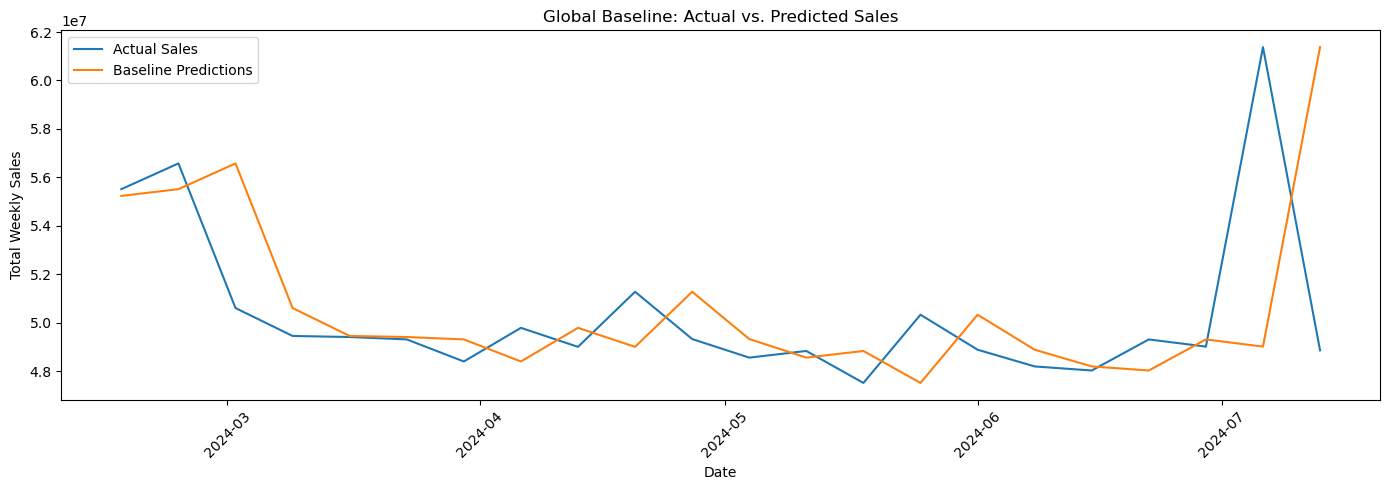

In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict using previous week's sales
y_pred_baseline = X_val["lag_1"]

# Evaluate baseline globally
baseline_mae = mean_absolute_error(y_val, y_pred_baseline)
baseline_rmse = np.sqrt(mean_squared_error(y_val, y_pred_baseline))

baseline_mape = (
    np.abs((y_val - y_pred_baseline) / y_val.replace(0, np.nan))
).mean() * 100

print("Global Baseline MAE:", round(baseline_mae, 2))
print("Global Baseline RMSE:", round(baseline_rmse, 2))
print("Global Baseline MAPE:", round(baseline_mape, 2), "%")

# Combine actual and predicted sales
global_results = pd.DataFrame({
    "date": val_data["date"].to_numpy(),
    "actual": y_val.to_numpy(),
    "predicted": y_pred_baseline.to_numpy()
})

# Aggregate sales across all stores and departments by date
global_daily_sales = global_results.groupby("date")[
    ["actual", "predicted"]
].sum().reset_index()

# Plot global actual vs. predicted sales
plt.figure(figsize=(14, 5))
plt.plot(global_daily_sales["date"], global_daily_sales["actual"], label="Actual Sales")
plt.plot(global_daily_sales["date"], global_daily_sales["predicted"], label="Baseline Predictions")

plt.title("Global Baseline: Actual vs. Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Model A  Results

- Evaluating MAE and RMSE for all Model A features
- Evaluating Predicted vs. Actual Results on 1 store + department combination

Global Validation MAE: 22281.05
Global Validation RMSE: 29639.1
Global Validation MAPE: 77.91 %


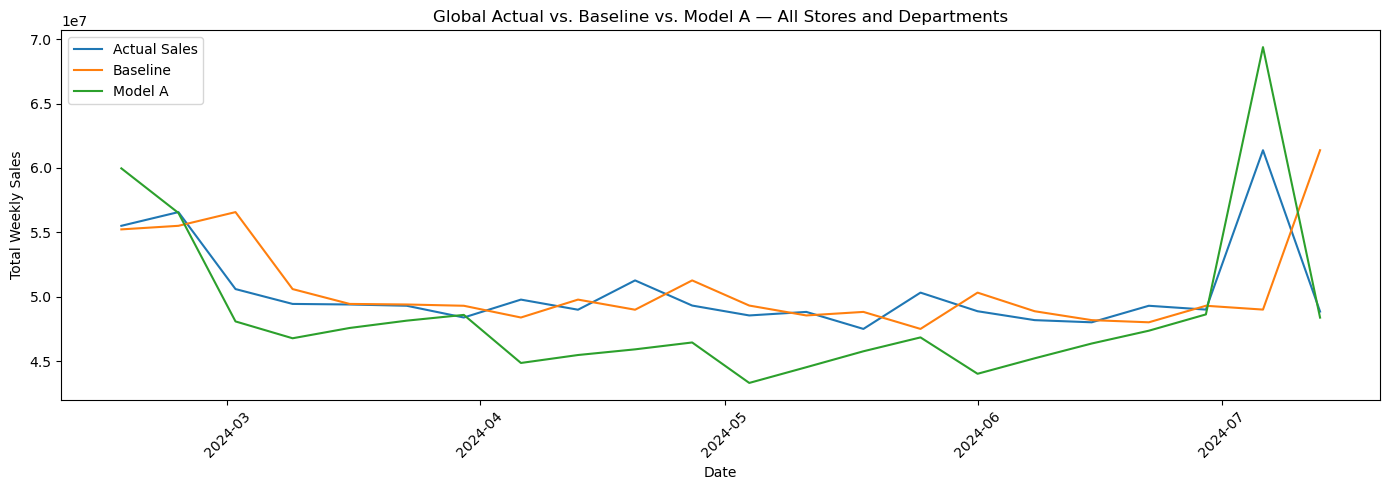

In [22]:
# Evaluate model globally
mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
global_mape = (
    np.abs((y_val - y_pred) / y_val.replace(0, np.nan))
).mean() * 100

print("Global Validation MAE:", round(mae, 2))
print("Global Validation RMSE:", round(rmse, 2))
print("Global Validation MAPE:", round(global_mape, 2), "%")


# Compare global actual vs. predicted vs. baseline sales by date
global_results = pd.DataFrame({
    "date": val_data["date"].to_numpy(),
    "actual": y_val.to_numpy(),
    "baseline_predicted": np.asarray(y_pred_baseline),
    "predicted": np.asarray(y_pred)
})

global_daily_sales = global_results.groupby("date")[
    ["actual", "baseline_predicted", "predicted"]
].sum().reset_index()

# Plot global actual vs. predicted sales
plt.figure(figsize=(14, 5))
plt.plot(global_daily_sales["date"], global_daily_sales["actual"], label="Actual Sales")
plt.plot(global_daily_sales["date"], global_daily_sales["baseline_predicted"], label="Baseline")
plt.plot(global_daily_sales["date"], global_daily_sales["predicted"], label="Model A")

plt.title("Global Actual vs. Baseline vs. Model A — All Stores and Departments")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [23]:
# Combine actual and predicted sales
error_data = pd.DataFrame({
    "date": val_data["date"].to_numpy(),
    "actual": y_val.to_numpy(),
    "predicted": np.asarray(y_pred)
})

# Create calendar features
error_data["date"] = pd.to_datetime(error_data["date"])
error_data["month"] = error_data["date"].dt.month
error_data["week_of_year"] = (
    error_data["date"].dt.isocalendar().week.astype(int)
)

# Calculate prediction errors
error_data["error"] = error_data["actual"] - error_data["predicted"]
error_data["absolute_error"] = error_data["error"].abs()
error_data["percentage_error"] = (
    error_data["error"] / error_data["actual"].replace(0, np.nan)
) * 100

# Aggregate across all stores and departments by date first
weekly_errors = error_data.groupby(
    ["date", "month", "week_of_year"]
).agg(
    actual=("actual", "sum"),
    predicted=("predicted", "sum"),
    absolute_error=("absolute_error", "sum")
).reset_index()

# Calculate global weekly error metrics
weekly_errors["error"] = weekly_errors["actual"] - weekly_errors["predicted"]
weekly_errors["absolute_percentage_error"] = (
    weekly_errors["error"].abs()
    / weekly_errors["actual"].replace(0, np.nan)
) * 100

# Table by month
monthly_errors = weekly_errors.groupby("month").agg(
    actual_sales=("actual", "mean"),
    predicted_sales=("predicted", "mean"),
    MAE=("error", lambda x: x.abs().mean()),
    mean_error=("error", "mean"),
    MAPE=("absolute_percentage_error", "mean")
).round(2)

monthly_errors

,actual_sales,predicted_sales,MAE,mean_error,MAPE
month,,,,,
2,56043068.28,58240034.13,2261850.41,-2196965.85,4.07
3,49431032.51,47840467.27,1671590.38,1590565.24,3.36
4,49844657.52,45682178.09,4162479.43,4162479.43,8.32
5,48804267.30,45118855.62,3685411.68,3685411.68,7.53
6,48681543.05,46327160.87,2354382.18,2354382.18,4.84
7,55116518.05,58883059.94,4235736.91,-3766541.89,7.00


## Model B - XGBoost Historical + Seasonality Features

Model B Validation MAE: 21929.0
Model B Validation RMSE: 29209.95
Model B Validation MAPE: 78.15 %


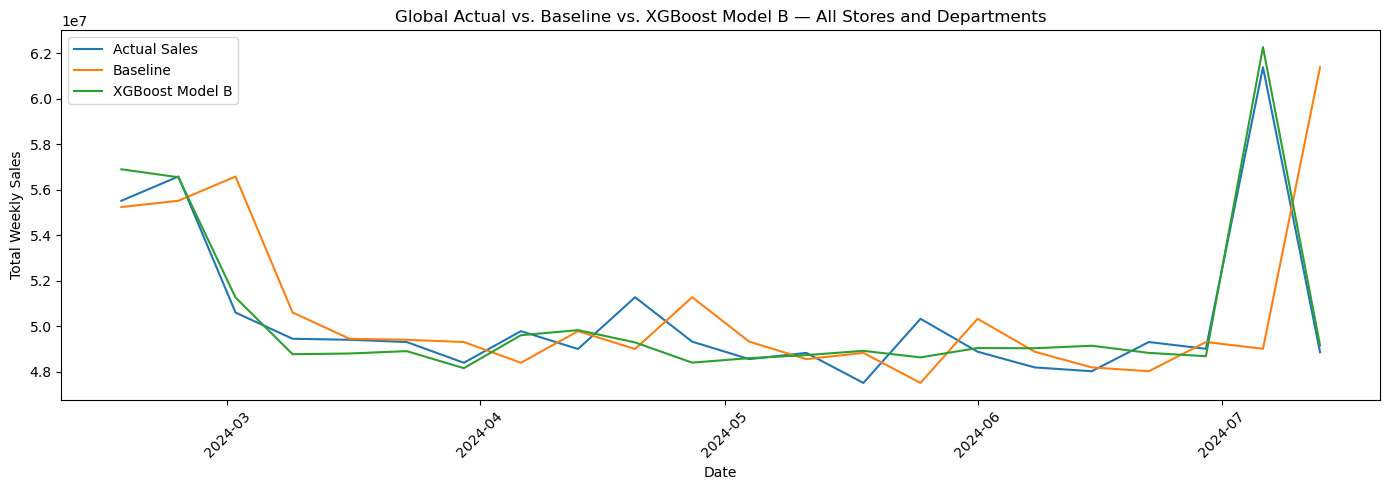

In [ ]:

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Train XGBoost Model B
model_B = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

model_B.fit(X_train[features_A], y_train)

# Generate predictions
y_pred_B = model_B.predict(X_val[features_A])

# Evaluate model at the row level
mae = mean_absolute_error(y_val, y_pred_B)
rmse = np.sqrt(mean_squared_error(y_val, y_pred_B))
global_mape = (
    np.abs((y_val - y_pred_B) / y_val.replace(0, np.nan))
).mean() * 100

print("Model B Validation MAE:", round(mae, 2))
print("Model B Validation RMSE:", round(rmse, 2))
print("Model B Validation MAPE:", round(global_mape, 2), "%")

# Compare global actual vs. predicted vs. baseline sales by date
global_results = pd.DataFrame({
    "date": val_data["date"].to_numpy(),
    "actual": y_val.to_numpy(),
    "baseline_predicted": np.asarray(y_pred_baseline),
    "predicted": np.asarray(y_pred_B)
})

global_daily_sales = global_results.groupby("date")[
    ["actual", "baseline_predicted", "predicted"]
].sum().reset_index()

# Plot global actual vs. predicted sales
plt.figure(figsize=(14, 5))
plt.plot(global_daily_sales["date"], global_daily_sales["actual"], label="Actual Sales")
plt.plot(global_daily_sales["date"], global_daily_sales["baseline_predicted"], label="Baseline")
plt.plot(global_daily_sales["date"], global_daily_sales["predicted"], label="XGBoost Model B")

plt.title("Global Actual vs. Baseline vs. XGBoost Model B — All Stores and Departments")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Model C - XGBoost Historical + Seasonal + Store Features

In [ ]:
# ==========================================
# MODEL C — PREPARE DATA
# ==========================================

features_C = features_A + ["store_id", "department", "store_size"]

# Create separate datasets for Model C
X_train_C = train_data[features_C].copy()
X_val_C = val_data[features_C].copy()
X_test_C = test_data[features_C].copy()

# Convert categorical columns
for col in ["store_id", "department"]:
    X_train_C[col] = X_train_C[col].astype("category")
    X_val_C[col] = X_val_C[col].astype("category")
    X_test_C[col] = X_test_C[col].astype("category")

# Train Model C
model_C = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    enable_categorical=True
)

model_C.fit(X_train_C, y_train)

# Generate predictions
y_pred_C = model_C.predict(X_val_C)

In [27]:

# ==========================================
# COMPARE MODEL RESULTS
# ==========================================

models = {
    "Baseline": y_pred_baseline,
    "Model A - Linear Regression": y_pred,
    "Model B - XGBoost": y_pred_B,
    "Model C - XGBoost + Store/Department": y_pred_C
}

results = []

for name, predictions in models.items():
    actual = np.asarray(y_val)
    predictions = np.asarray(predictions)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
        "MAPE (%)": (
            np.abs(
                (actual - predictions)
                / np.where(actual == 0, np.nan, actual)
            ).mean() * 100
        )
    })

model_comparison = pd.DataFrame(results)

display(
    model_comparison.style.format({
        "MAE": "{:,.2f}",
        "RMSE": "{:,.2f}",
        "MAPE (%)": "{:.2f}%"
    }).set_properties(**{
        "min-width": "180px",
        "text-align": "right"
    })
)

,Model,MAE,RMSE,MAPE (%)
0,Baseline,"29,060.31","40,586.40",93.20%
1,Model A - Linear Regression,"22,281.05","29,639.10",77.91%
2,Model B - XGBoost,"21,929.00","29,209.95",78.15%
3,Model C - XGBoost + Store/Department,"21,448.84","28,383.44",75.56%


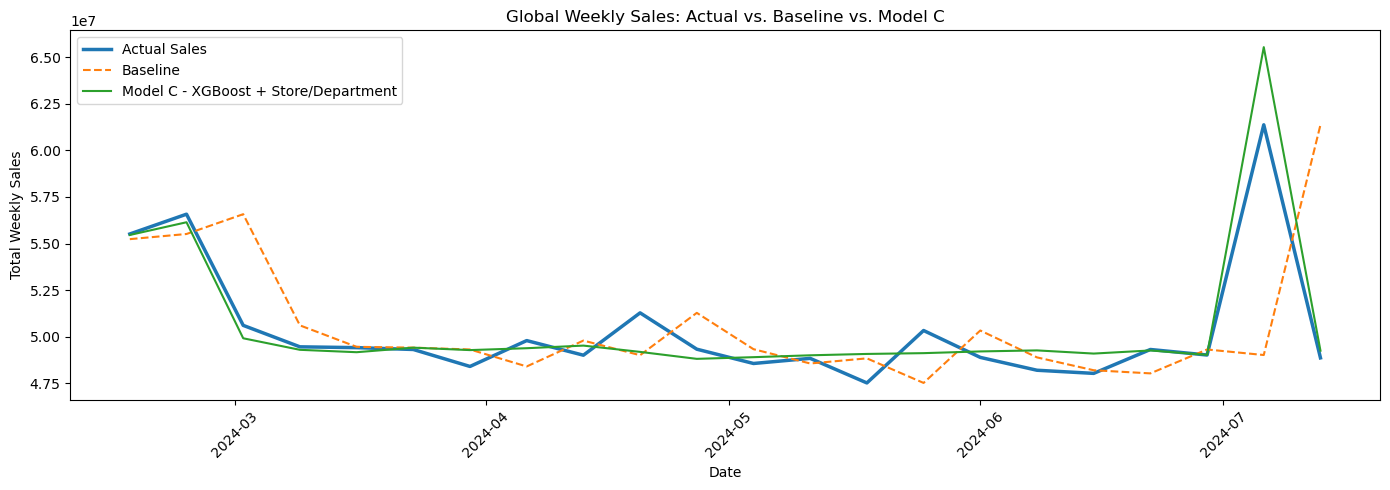

In [29]:

# Aggregate global weekly sales
global_results = pd.DataFrame({
    "date": val_data["date"].to_numpy(),
    "actual": y_val.to_numpy(),
    "baseline": np.asarray(y_pred_baseline),
    "model_C": np.asarray(y_pred_C)
})

global_weekly_sales = global_results.groupby("date", as_index=False)[
    ["actual", "baseline", "model_C"]
].sum()

# Plot comparison
plt.figure(figsize=(14, 5))

plt.plot(global_weekly_sales["date"], global_weekly_sales["actual"],
         label="Actual Sales", linewidth=2.5)
plt.plot(global_weekly_sales["date"], global_weekly_sales["baseline"],
         label="Baseline", linestyle="--")
plt.plot(global_weekly_sales["date"], global_weekly_sales["model_C"],
         label="Model C - XGBoost + Store/Department")

plt.title("Global Weekly Sales: Actual vs. Baseline vs. Model C")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Run on Test Set

Model C Test MAE: 26939.01
Model C Test RMSE: 37354.93
Model C Test MAPE: 77.11 %


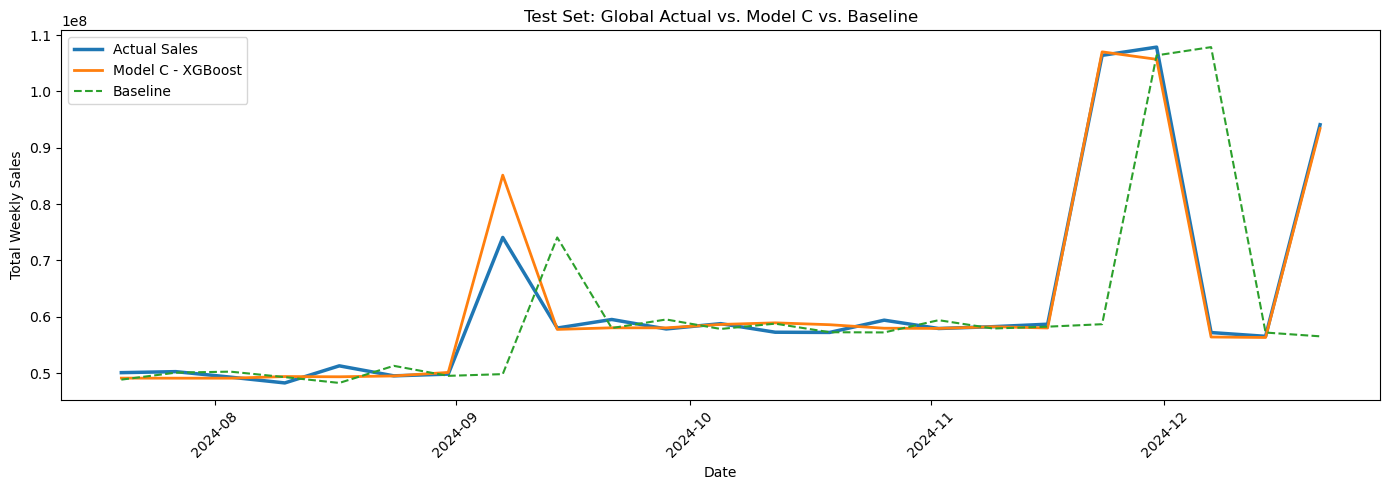

In [36]:

# ==========================================
# 1. PREDICT USING MODEL C
# ==========================================
y_pred_C_test = model_C.predict(X_test_C)

# ==========================================
# 2. GENERATE BASELINE PREDICTIONS
# ==========================================
y_pred_baseline_test = X_test_C["lag_1"].to_numpy()

# ==========================================
# 3. EVALUATE MODEL C
# ==========================================
mae_test = mean_absolute_error(y_test, y_pred_C_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_C_test))

actual = y_test.to_numpy()

mape_test = (
    np.abs((actual - y_pred_C_test) / np.where(actual == 0, np.nan, actual))
).mean() * 100

print("Model C Test MAE:", round(mae_test, 2))
print("Model C Test RMSE:", round(rmse_test, 2))
print("Model C Test MAPE:", round(mape_test, 2), "%")

# ==========================================
# 4. AGGREGATE GLOBAL WEEKLY SALES
# ==========================================
test_results = pd.DataFrame({
    "date": pd.to_datetime(test_data["date"]).to_numpy(),
    "actual": actual,
    "predicted": y_pred_C_test,
    "baseline": y_pred_baseline_test
})

global_test_sales = test_results.groupby("date", as_index=False)[
    ["actual", "predicted", "baseline"]
].sum()

# ==========================================
# 5. PLOT RESULTS
# ==========================================
plt.figure(figsize=(14, 5))

plt.plot(global_test_sales["date"], global_test_sales["actual"],
         label="Actual Sales", linewidth=2.5)

plt.plot(global_test_sales["date"], global_test_sales["predicted"],
         label="Model C - XGBoost", linewidth=2)

plt.plot(global_test_sales["date"], global_test_sales["baseline"],
         label="Baseline", linestyle="--")

plt.title("Test Set: Global Actual vs. Model C vs. Baseline")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Analysis of Model

In [31]:

# ==========================================
# MODEL RESULTS: ACTUAL VS. PREDICTED
# ==========================================

results = pd.DataFrame({
    "date": val_data["date"].to_numpy(),
    "actual": y_val.to_numpy(),
    "predicted": np.asarray(y_pred_C)  # Replace with model predictions
})

# Add month and week number
results["date"] = pd.to_datetime(results["date"])
results["Month"] = results["date"].dt.month
results["Week Number"] = results["date"].dt.isocalendar().week.astype(int)

# Aggregate global sales by week
results = results.groupby(
    ["Month", "Week Number"], as_index=False
)[["actual", "predicted"]].sum()

# Calculate percentage error
results["% Error"] = (
    (results["predicted"] - results["actual"])
    / results["actual"].replace(0, np.nan)
) * 100

# Rename columns
results = results.rename(columns={
    "actual": "Actual Sales",
    "predicted": "Predicted Sales"
})

# Display table
display(
    results.style.format({
        "Actual Sales": "{:,.2f}",
        "Predicted Sales": "{:,.2f}",
        "% Error": "{:+.2f}%"
    }).set_properties(**{
        "min-width": "140px",
        "text-align": "right"
    })
)


,Month,Week Number,Actual Sales,Predicted Sales,% Error
0,2,7,"55,511,143.56","55,458,128.00",-0.10%
1,2,8,"56,574,993.01","56,141,808.00",-0.77%
2,3,9,"50,601,429.92","49,908,032.00",-1.37%
3,3,10,"49,448,658.53","49,288,328.00",-0.32%
4,3,11,"49,404,919.29","49,159,452.00",-0.50%
5,3,12,"49,305,981.83","49,403,740.00",+0.20%
6,3,13,"48,394,172.98","49,272,848.00",+1.82%
7,4,14,"49,783,854.05","49,374,332.00",-0.82%
8,4,15,"48,998,891.31","49,514,484.00",+1.05%
9,4,16,"51,273,883.38","49,176,780.00",-4.09%


In [33]:
# Was there a correlation between economic values and weekly sales that the model didn't pickup? No visible correlation between economic factors and weekly sales
# Did the predicted sales struggle with store_type? Yes it did with predicted values resulting in > +/- 5%
# Did the predicted sales struggle with certain types of departments?

## Experiment Log Results

In [ ]:
import pandas as pd
import os

results_file = "model_experiment_log.csv"

# Load existing results or create a new log
if os.path.exists(results_file):
    experiment_log = pd.read_csv(results_file)
else:
    experiment_log = pd.DataFrame(columns=[
        "experiment_id",
        "model_name",
        "features",
        "MAE",
        "RMSE",
        "MAPE",
        "observations"
    ])

In [32]:
# ==========================================
# SAVE MODEL EXPERIMENT RESULTS
# ==========================================

from datetime import datetime
import os

results_file = r"C:\Users\paolo\OneDrive\Desktop\Data Science Projects\02_retail_sales_forecasting_SYN\model_expirment_results.csv"

experiments = [
    {
        "model_name": "Baseline",
        "features": ["lag_1"],
        "y_pred": y_pred_baseline
    },
    {
        "model_name": "Model A - Linear Regression",
        "features": features_A,
        "y_pred": y_pred
    },
    {
        "model_name": "Model B - XGBoost",
        "features": features_A,
        "y_pred": y_pred_B
    },
    {
        "model_name": "Model C - XGBoost + Store/Department",
        "features": features_C,
        "y_pred": y_pred_C
    }
]

# Load existing experiment log or create a new one
if os.path.exists(results_file):
    experiment_log = pd.read_csv(results_file)
else:
    experiment_log = pd.DataFrame(columns=[
        "experiment_id", "date_time", "model_name",
        "features", "MAE", "RMSE", "MAPE"
    ])

new_results = []
timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

for experiment in experiments:
    predictions = np.asarray(experiment["y_pred"])
    actual = np.asarray(y_val)

    mae = mean_absolute_error(actual, predictions)
    rmse = np.sqrt(mean_squared_error(actual, predictions))

    actual_series = pd.Series(actual)
    mape = (
        np.abs(
            (actual_series - predictions)
            / actual_series.replace(0, np.nan)
        )
    ).mean() * 100

    new_results.append({
        "experiment_id": len(experiment_log) + len(new_results) + 1,
        "date_time": timestamp,
        "model_name": experiment["model_name"],
        "features": ", ".join(experiment["features"]),
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "MAPE": round(mape, 2)
    })

# Append and save results
experiment_log = pd.concat(
    [experiment_log, pd.DataFrame(new_results)],
    ignore_index=True
)

experiment_log.to_csv(results_file, index=False)

print("Experiment results saved to:")
print(results_file)

display(experiment_log)

Experiment results saved to:
C:\Users\paolo\OneDrive\Desktop\Data Science Projects\02_retail_sales_forecasting_SYN\model_expirment_results.csv


,experiment_id,date_time,model_name,features,MAE,RMSE,MAPE
0,1,2026-11-02 18:20:02,Baseline,lag_1,29060.31,40586.40,93.20
1,2,2026-11-02 18:20:02,Model A - Linear Regression,"lag_1, lag_2, lag_4, lag_8, rolling_mean_2, ro...",22281.05,29639.10,77.91
2,3,2026-11-02 18:20:02,Model B - XGBoost,"lag_1, lag_2, lag_4, lag_8, rolling_mean_2, ro...",21929.00,29209.95,78.15
3,4,2026-11-02 19:02:18,Baseline,lag_1,29060.31,40586.40,93.20
4,5,2026-11-02 19:02:18,Model A - Linear Regression,"lag_1, lag_2, lag_4, lag_8, rolling_mean_2, ro...",22281.05,29639.10,77.91
5,6,2026-11-02 19:02:18,Model B - XGBoost,"lag_1, lag_2, lag_4, lag_8, rolling_mean_2, ro...",21929.00,29209.95,78.15
6,7,2026-11-02 19:02:18,Model C - XGBoost + Store/Department,"lag_1, lag_2, lag_4, lag_8, rolling_mean_2, ro...",21448.84,28383.44,75.56
